# Monte Carlo Simulation of Mini Model for NiX2
### Purposes : 
simulate the mini model $$ $$ and track how topological charge, susceptibility evolves with temperature

### Step 1 : Import

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from nix2_model_builders import *
from nix2_mc import MonteCarloNiX2, KB_MEV_PER_K

In [3]:
import matplotlib.pyplot as plt
from plotting_3d_spins import (
    PLOT_CONFIG, plot_spin_config, plot_spin_texture, plot_spin_angles, plot_curves,
)
plt.rcParams.update(PLOT_CONFIG)

### Step 2 : Lattice

In [4]:
Lmuc = 8
Nmuc = 6

Na = Nb = Nmuc * Lmuc

lattice_geometry = "triangular"

nix2_lattice = build_nix2_lattice(Na, Nb, geometry=lattice_geometry)

### Step 3 : mini Model

for mini model, only parameters $(J^{\text{iso}}_1, J^{\text{iso}}_2, J^{\text{iso}}_3, J^{\text{aniso}}_1, J^{\text{aniso}}_3, A_{zz})$ are considered, the anisotropic exchange interaction was believed to be important to the spontaneous formation of anti-biskyrmion lattice in NiI2.

<div align="center">
  <img src="Figures_NiX2/snapshot_parameter_table.png"
       alt="Spin model parameter table"
       width="350">
</div>

mini model was used to describe the NiX2 family before 2023, until the 2023 PRL paper gave a more sophisticated model for the proper screw order.

In [5]:
# exchange
J1iso = -7.0  # meV
Jxx = -1.0
Jyy = 1.4
Jzz = -0.3
Jyz = -1.4
# Jyz = -0.98
J1mat = J1iso * np.eye(3) + np.array([[Jxx, 0.0, 0.0],
                                      [0.0, Jyy, Jyz],
                                      [0.0, Jyz, Jzz]])

J2iso = -0.3   # meV
J3iso = +5.8  # meV

# single-ion anisotropy
Azz = 0.6

model_params = {
    "J1mat": J1mat,
    "J2iso": J2iso,
    "J3": J3iso,
    "Azz": Azz,
    "B_biquad": 0.0,
    "B_field": (0.0, 0.0, 0.0),
}

# build the spin model
nix2_model = build_nix2_model(J1mat, J3=J3iso, J2iso=J2iso, Azz=Azz, 
                              B_biquad=0.0, B_field=(0.0, 0.0, 0.0), geometry=lattice_geometry)

### Step 4 : MC simulator

In [6]:
import secrets

mc_seed = secrets.randbits(128)

nix2_mc = MonteCarloNiX2(lattice=nix2_lattice, spin_model=nix2_model, seed=mc_seed)

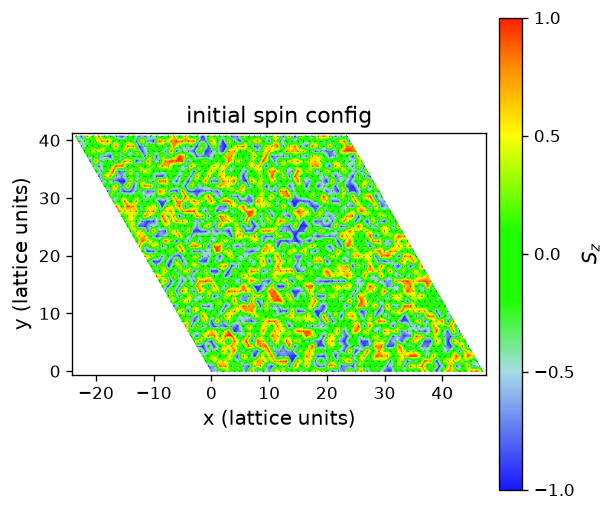

In [7]:
# Current spin configuration: Sz background and in-plane spin arrows.
ax = plot_spin_texture(
    nix2_mc.spin_config, nix2_mc.lat,
    title="initial spin config", figsize=(5, 5),
)
plt.show()

### Step 5 : Prepare for MC Simulation

In [8]:
from nix2_mc_protocols import *

In [ ]:
# # temperatures
# TK_init_list = [70, 50, 20]
# TK_final_list = [51, 21, 1]
# cooling_method_list = ["linear", "linear", "linear"]
# cooling_rate_list = [15, 25, 20]

# TK_list = set_temperature_schedule(
#     TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
# )

In [9]:
# temperatures
TK_init_list = [55]
TK_final_list = [20]
cooling_method_list = ["linear"]
cooling_rate_list = [35]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [11]:
num_eq_sweeps = 15000
converg_per_every = 10
num_meas_sweeps = 35000
meas_per_every = 5

In [12]:
obs = ["E", "Q", "chi"]
measurements = make_measurements(
    nix2_mc,
    observables = obs,
)

In [13]:
mc_parameters={
    # lattice parameters
    "Nx": Na,
    "Ny": Nb,
    "Ns": nix2_model.Ns,
    "geometry": lattice_geometry,
    
    # model parameters
    "model_params": model_params,

    # Monte Carlo parameters
    "seed": mc_seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    "observables": obs,
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nix2_simulation_results", parameters=mc_parameters,
                                    prefix="NiX2_annealing_")

### Step 6 : start Monte Carlo Simulation

In [14]:
S_q_data = []
Q_data = []
chi_data = []

N_total = nix2_mc.lat.N_total

# set proposal angle for the current temperature
nix2_mc.set_proposal_angle(T_in_meV=TK_list[0]*KB_MEV_PER_K)

for temperature_index, temperature_K in enumerate(TK_list):
    temperature_in_meV = temperature_K * KB_MEV_PER_K

    convergence_data = []
    stat_Q_data = []
    stat_Q2_data = []

    # ================================
    # equilibration sweeps
    # ================================
    for sweep in range(num_eq_sweeps):
        nix2_mc.mc_sweep(temperature_in_meV)
        if sweep % converg_per_every == 0:
            E_tot = nix2_mc.total_energy()
            convergence_data.append((E_tot))

    # ================================
    # measurement sweeps
    # ================================
    for sweep in range(num_meas_sweeps):
        nix2_mc.mc_sweep(temperature_in_meV)
        if sweep % meas_per_every == 0:
            Q, Q2 = nix2_mc.topological_charge()
            # chi = (Q2 - Q**2) / temperature_in_meV # don't use it, this is exactly 0
            stat_Q_data.append(Q)
            stat_Q2_data.append(Q2)

    # ================================
    # statistical analysis
    # ================================
    # statistical average of Q
    Q_now = np.mean(stat_Q_data)
    Q_data.append(Q_now/(Nmuc**2)) # divided by the number of magnetic unit cells

    absQ_now = np.mean(np.abs(stat_Q_data))
    chi_now = (np.mean(stat_Q2_data) - absQ_now**2)/(Nmuc**4 * temperature_in_meV)
    chi_data.append(chi_now)

    # spin structure factor
    # q1, q2, S_q = nix2_mc.spin_structure_factor()
    # S_q_data.append(S_q)

    # print information
    print(f"Temperature (K): {temperature_K}, <Q>: {np.mean(stat_Q_data)}, <chi>: {(np.mean(stat_Q2_data) - np.mean(stat_Q_data)**2)}")

    # Save immediately after this temperature finishes.
    save_temperature_results(
        current_folder, nix2_mc, temperature_index, temperature_K,
        observables={
            # "convergence_energy": convergence_data,
            "topo_Q": stat_Q_data, 
            "topo_Q2": stat_Q2_data,
            # "q1": q1, "q2": q2, "spin_structure_factor": S_q,
        },
        parameters=None
    )

Temperature (K): 55.0, <Q>: 0.465142857142857, <chi>: 85.55421355102041
Temperature (K): 53.970588235294116, <Q>: 0.157142857142858, <chi>: 79.67073469387755


KeyboardInterrupt: 

### Step 7 : Plotting final spin configuration

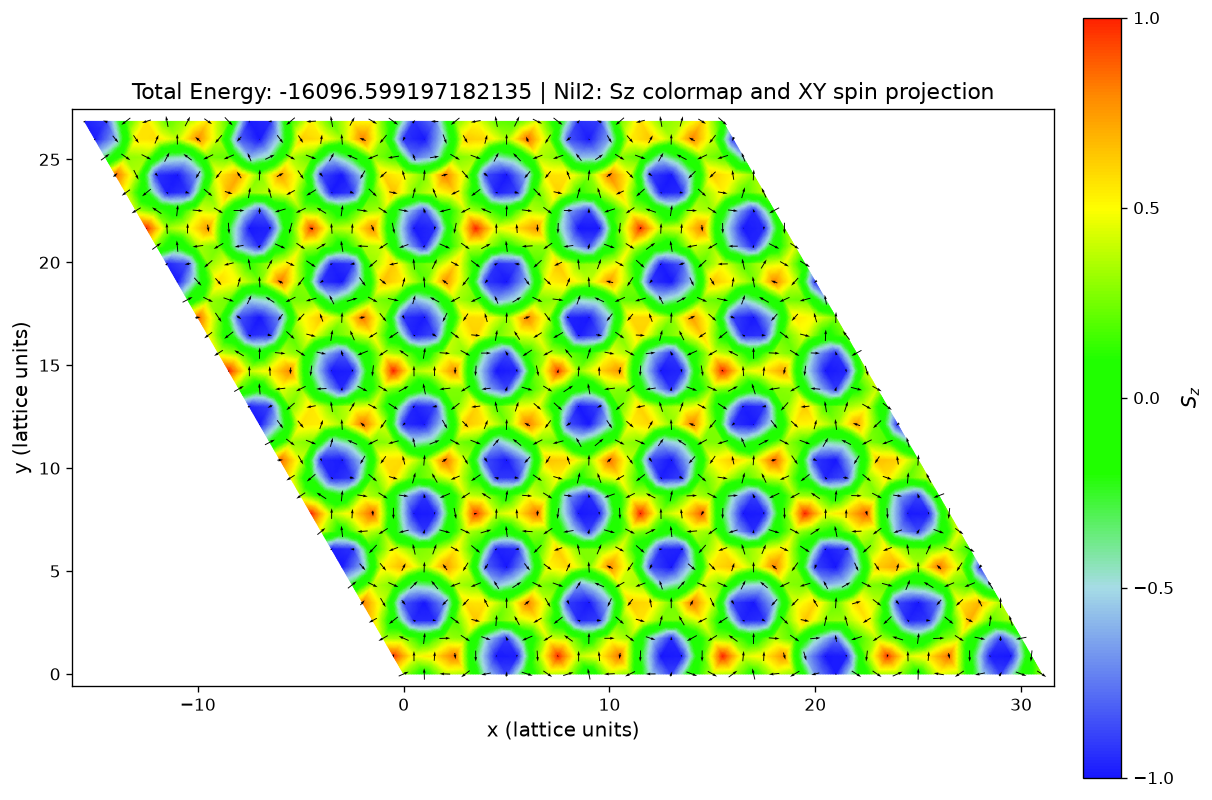

In [23]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=nix2_mc.spin_config,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: Sz colormap and XY spin projection",
    figsize=(10, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
)
plt.show()

In [ ]:
from plotting_3d_spins import plot_curves

fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], abs(results["Q_data"]), results["chi_data"],
    xlabel="Temperature (K)",
    ylabel1="Q per magnetic unit cell", ylabel2=r"$\chi$ (1/meV)",
    label1="Q", label2=r"$\chi$",
    flag_show=True,
)

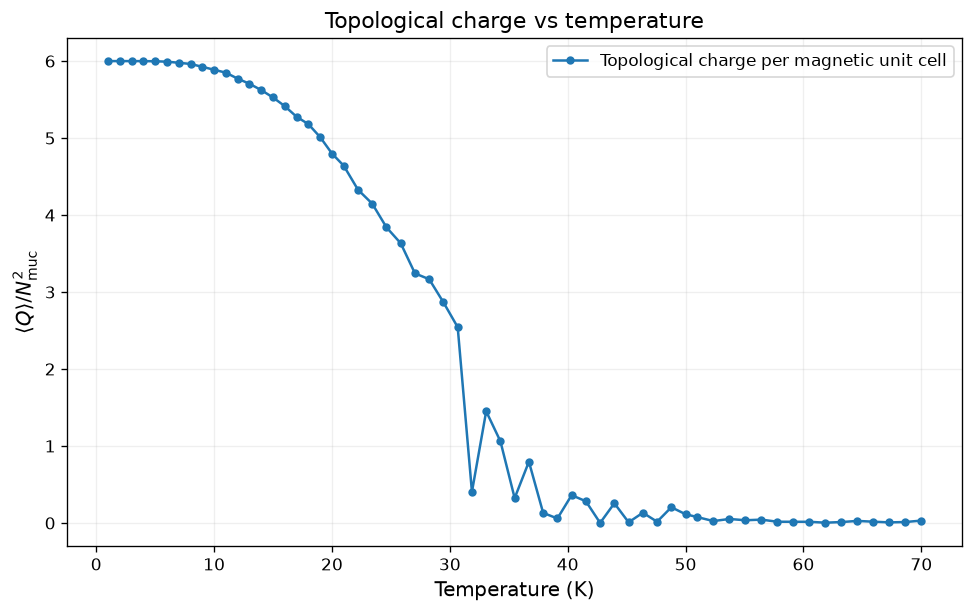

In [25]:
from plotting_3d_spins import plot_curves

fig, ax, _ = plot_curves(
    TK_list[:len(Q_data)], np.abs(Q_data),
    xlabel="Temperature (K)",
    ylabel1=r"$\langle Q \rangle / N_{\mathrm{muc}}$",
    label1="Topological charge per magnetic unit cell",
    title="Topological charge vs temperature",
    colors=("tab:blue", "firebrick"), figsize=(8, 5),
    flag_show=True,
)